# Klasifikasi SVM — PBL Harga Properti

Bagian dari perbandingan 3 metode klasifikasi: **kNN, SVM, Naive Bayes**.
Data: `data_preprocessed.csv` (hasil `Preprocessing.ipynb`, preprocessing identik untuk semua metode).

Target: `kelas_harga` (Murah / Sedang / Mahal) — 15.000 data, 5 fitur ter-scaling.

## 1. Load Data & Split (80:20, stratified, random_state=42)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv('data_preprocessed.csv')
X = df.drop(columns=['kelas_harga'])
y = df['kelas_harga']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')
print(df['kelas_harga'].value_counts())

Train: 12000 | Test: 3000
kelas_harga
Sedang    5020
Mahal     4999
Murah     4981
Name: count, dtype: int64


## 2. Perbandingan Kernel (linear vs polynomial vs RBF, parameter default)

In [2]:
hasil_kernel = []
for kernel in ['linear', 'poly', 'rbf']:
    svm = SVC(kernel=kernel, random_state=42)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    hasil_kernel.append({
        'Kernel': kernel,
        'Akurasi Train': svm.score(X_train, y_train),
        'Akurasi': accuracy_score(y_test, y_pred),
        'Precision (macro)': precision_score(y_test, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro'),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
    })
    print(f'kernel {kernel:7s} -> train: {hasil_kernel[-1]["Akurasi Train"]:.4f} | test: {hasil_kernel[-1]["Akurasi"]:.4f}')

tabel_kernel = pd.DataFrame(hasil_kernel).round(4)
tabel_kernel

kernel linear  -> train: 0.6459 | test: 0.6513


kernel poly    -> train: 0.6043 | test: 0.6143


kernel rbf     -> train: 0.6721 | test: 0.6673


,Kernel,Akurasi Train,Akurasi,Precision (macro),Recall (macro),F1 (macro)
0,linear,0.6459,0.6513,0.6492,0.6520,0.6388
1,poly,0.6043,0.6143,0.6804,0.6146,0.6099
2,rbf,0.6721,0.6673,0.6577,0.6679,0.6561


## 3. Hyperparameter Tuning (GridSearchCV pada kernel RBF — kernel terbaik)

Catatan: GridSearchCV pada 12.000 data training membutuhkan waktu beberapa menit.

In [3]:
param_grid = {'C': [0.1, 1, 10, 100],
              'gamma': [0.01, 0.1, 1, 'scale']}
grid = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

print('Parameter terbaik:', grid.best_params_)
print(f'Skor CV terbaik  : {grid.best_score_:.4f}')

Parameter terbaik: {'C': 1, 'gamma': 1}
Skor CV terbaik  : 0.6722


## 4. Model Final SVM (hasil tuning)

In [4]:
svm_final = grid.best_estimator_
y_pred_final = svm_final.predict(X_test)

print(f"Akurasi  : {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_final, average='macro'):.4f}")
print()
print(classification_report(y_test, y_pred_final))

Akurasi  : 0.6727
Precision: 0.6625
Recall   : 0.6732
F1-score : 0.6616

              precision    recall  f1-score   support

       Mahal       0.74      0.78      0.76      1000
       Murah       0.68      0.82      0.74       996
      Sedang       0.57      0.42      0.48      1004

    accuracy                           0.67      3000
   macro avg       0.66      0.67      0.66      3000
weighted avg       0.66      0.67      0.66      3000



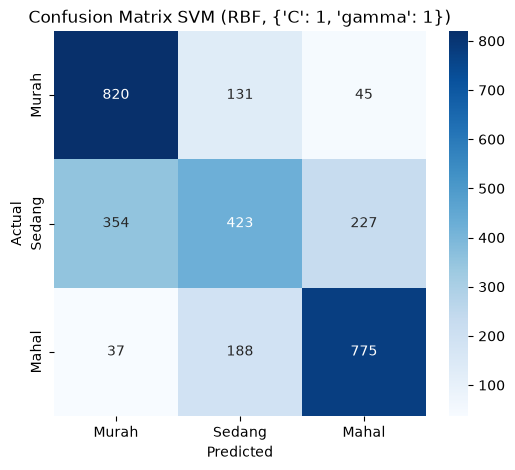

In [5]:
cm = confusion_matrix(y_test, y_pred_final, labels=['Murah', 'Sedang', 'Mahal'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Murah', 'Sedang', 'Mahal'],
            yticklabels=['Murah', 'Sedang', 'Mahal'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix SVM (RBF, {grid.best_params_})')
plt.show()

## 5. Simpan Hasil (untuk notebook Perbandingan)

In [6]:
hasil_svm = {
    'Metode': 'SVM',
    'Konfigurasi': f"kernel=rbf, C={grid.best_params_['C']}, gamma={grid.best_params_['gamma']}",
    'Akurasi': accuracy_score(y_test, y_pred_final),
    'Precision': precision_score(y_test, y_pred_final, average='macro'),
    'Recall': recall_score(y_test, y_pred_final, average='macro'),
    'F1': f1_score(y_test, y_pred_final, average='macro'),
}
pd.DataFrame([hasil_svm]).to_csv('hasil_svm.csv', index=False)
print('Tersimpan: hasil_svm.csv')
pd.DataFrame([hasil_svm]).round(4)

Tersimpan: hasil_svm.csv


,Metode,Konfigurasi,Akurasi,Precision,Recall,F1
0,SVM,"kernel=rbf, C=1, gamma=1",0.6727,0.6625,0.6732,0.6616


## 6. Analisis SVM

**(a) Perbandingan kernel (parameter default):**

| Kernel | Akurasi Train | Akurasi Test | F1 (macro) |
|---|---|---|---|
| linear | 0.6459 | 0.6513 | 0.6388 |
| poly | 0.6043 | 0.6143 | 0.6099 |
| **rbf** | **0.6721** | **0.6673** | **0.6561** |

Kernel **RBF terbaik** — data properti memiliki batas kelas non-linier (harga dipengaruhi kombinasi fitur yang tidak linier). Polynomial justru terburuk (train < test menandakan underfitting; derajat 3 default kurang fleksibel). Linear berada di tengah, artinya sebagian pola masih bisa ditangkap bidang lurus.

**(b) Hyperparameter tuning:** GridSearchCV (C ∈ {0.1,1,10,100}, gamma ∈ {0.01,0.1,1,'scale'}, cv=3) memilih **C=1, gamma=1** dengan skor CV 0.6722. Model tuned mencapai akurasi test **0.6727** (F1 0.6616) — sedikit di atas RBF default (0.6673). Peningkatan kecil menunjukkan parameter default sudah cukup dekat dengan optimum; tuning tetap penting untuk memastikan tidak ada konfigurasi yang jauh lebih baik.

**(c) Performa per kelas:** sama seperti kNN — **Mahal** (F1=0.76) dan **Murah** (F1=0.74) relatif mudah, **Sedang** paling sulit (F1=0.48, recall 0.42) karena posisinya di antara dua kelas lain. Recall Murah tertinggi (0.82): model jarang melewatkan properti murah.

**(d) Kesimpulan:** model final **SVM RBF (C=1, gamma=1)** dengan akurasi test **0.6727** — setara kNN, dengan keunggulan training yang lebih efisien untuk prediksi data baru (hanya bergantung pada support vector, bukan seluruh data training).